A sua tabela meteorológica é [((1, 2, 2026), 12.0, 26.0, 0.02), ((2, 2, 2026), 14.0, 20.0, 0.03)]

    ---Menu---
    1: Calcular a temperatura média de cada dia;
    2: Guardar a tabela meteorológica num ficheiro;
    3: Carregar a tabela meteorológica de um ficheiro;
    4: Calcular a temperatura mínima mais baixa registada na tabela;
    5: Calcular a amplitude térmica de cada dia;
    6: Calcular o dia em que a precipitação registada teve o seu valor máximo;
    7: Dias com precipitação superior a um limite escolhido;
    8: Maior número de dias consecutivos com precipitação abaixo do limite escolhido;
    9: Gráficos da temperatura mínima, máxima e de pluviosidade;
    0: Sair da aplicação
    
[((1, 2, 2026), 19.0), ((2, 2, 2026), 17.0)]

    ---Menu---
    1: Calcular a temperatura média de cada dia;
    2: Guardar a tabela meteorológica num ficheiro;
    3: Carregar a tabela meteorológica de um ficheiro;
    4: Calcular a temperatura mínima mais baixa registada na tabela;
    5

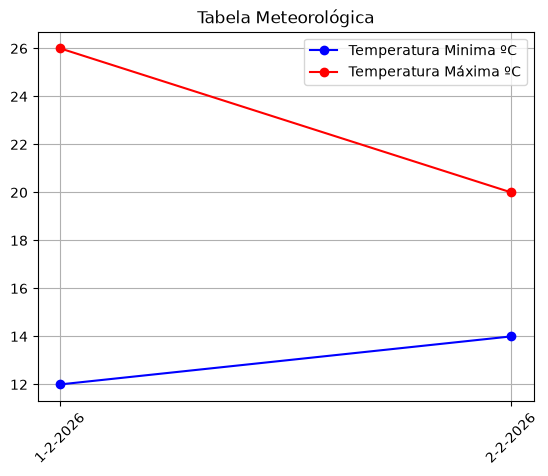

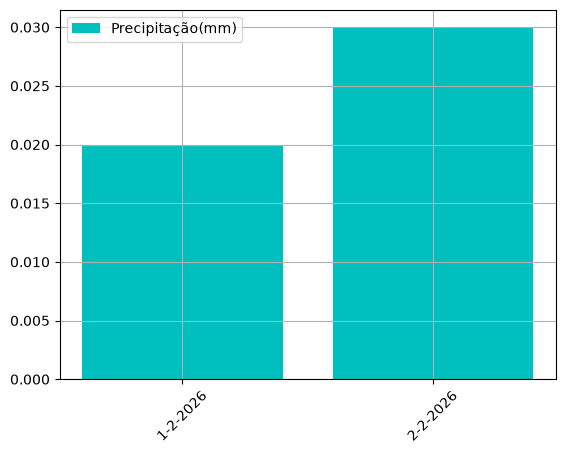


    ---Menu---
    1: Calcular a temperatura média de cada dia;
    2: Guardar a tabela meteorológica num ficheiro;
    3: Carregar a tabela meteorológica de um ficheiro;
    4: Calcular a temperatura mínima mais baixa registada na tabela;
    5: Calcular a amplitude térmica de cada dia;
    6: Calcular o dia em que a precipitação registada teve o seu valor máximo;
    7: Dias com precipitação superior a um limite escolhido;
    8: Maior número de dias consecutivos com precipitação abaixo do limite escolhido;
    9: Gráficos da temperatura mínima, máxima e de pluviosidade;
    0: Sair da aplicação
    
A tua aplicação fechou!


In [15]:
# TabMeteo = [(data,tmin,tmax,prec)]
    # data = (Int,Int,Int)
    # tmin = Float
    # tmax = Float
    # prec = Float


def medias(tabMeteo):
    res = []
    for x in tabMeteo:
        data, tmin, tmax, *_ = x  
        media = (tmax + tmin)/2
        res.append((data,media))  
    return res

def guardaTabMeteo(t, fnome):
    file = open(fnome, "w")
    for dias in t:
        data, tmin, tmax, prec = dias
        ano, mes, dia = data
        file.write(f"{ano}-{mes}-{dia}|{tmin}|{tmax}|{prec}\n")
    file.close()

def carregaTabMeteo(fnome):
    res = []
    file = open(fnome, "r")
    for linha in file:
        campos = linha.split("|") 
        c = campos[0].split("-") 
        data = (int(c[0]),int(c[1]),int(c[2])) 
        res.append((data,float(campos[1]),float(campos[2]),float(campos[3])))
    file.close() 
    return res

def minMin(tabMeteo):
    minima = tabMeteo[0][1]
    for x in tabMeteo:
        data, tmin, *_ = x
        if tmin < minima:
            minima = tmin

    return minima

def amplTerm(tabMeteo):
    res = []
    for x in tabMeteo:
        data, tmin, tmax, *_ = x
        amplitude = tmax - tmin
        res.append((data, amplitude))
    return res 

def maxChuva(tabMeteo):
    max_prec = -1
    for x in tabMeteo:
        data, tmin, tmax, prec = x
        if prec > max_prec :
            max_prec = prec
            max_data = data
        
    return (max_data, max_prec)

def diasChuvosos(tabMeteo, p):
    res = []
    for x in tabMeteo:
        data, tmin, tmax, prec = x
        if prec > p:
            res.append((data,prec))
    return res

def maxPeriodoCalor(tabMeteo, p):
    maximo = 0
    i = 0
    for x in tabMeteo:
        data, tmin, tmax, prec = x
        if prec < p:
            i = i + 1
            if i > maximo:
                maximo = i
        else:
            i = 0
    return maximo

import matplotlib.pyplot as plt

def grafTabMeteo(t):
    y_min = [tmin for data, tmin, *_ in t]
    y_max = [tmax for data, tmin, tmax, *_ in t]
    y_prec = [p for data, tmin, tmax, p in t]
    x = [f"{data[0]}-{data[1]}-{data[2]}" for data, *_ in t]
    plt.plot(x, y_min, color = "blue", marker = "o", label = "Temperatura Minima ºC")
    plt.plot(x, y_max, color = "red", marker = "o", label = "Temperatura Máxima ºC")
    plt.title("Tabela Meteorológica")
    plt.xticks(rotation = 45) 
    plt.legend() 
    plt.grid() 
    plt.show()
    

    plt.bar(x, y_prec, color = "c", label = "Precipitação(mm)")
    plt.xticks(rotation = 45)
    plt.grid()
    plt.legend()
    plt.show()
    return


def menu():
    print("""
    ---Menu---
    1: Calcular a temperatura média de cada dia;
    2: Guardar a tabela meteorológica num ficheiro;
    3: Carregar a tabela meteorológica de um ficheiro;
    4: Calcular a temperatura mínima mais baixa registada na tabela;
    5: Calcular a amplitude térmica de cada dia;
    6: Calcular o dia em que a precipitação registada teve o seu valor máximo;
    7: Dias com precipitação superior a um limite escolhido;
    8: Maior número de dias consecutivos com precipitação abaixo do limite escolhido;
    9: Gráficos da temperatura mínima, máxima e de pluviosidade;
    0: Sair da aplicação
    """)


TabMeteo = []
N = int(input("Quantos dias tem a sua tabela meteorológica?"))
while N > 0:
    dia = int(input("Introduza o dia"))
    mes = int(input("Introduza o mes"))
    ano = int(input("Introduza o ano"))
    data = (dia, mes, ano)
    tmin = float(input("Introduza a Temperatura mínima (ºC)"))
    tmax = float(input("Introduza a Temperatura máxima (ºC)"))
    prec = float(input("Introduza a Precipitação (mm)"))
    TabMeteo.append((data, tmin, tmax, prec))
    N = N - 1
print(f"A sua tabela meteorológica é {TabMeteo}")
menu()
i = int(input("Qual é a operação que deseja realizar?"))
while i != 0:
    if i == 1:
        print(medias(TabMeteo))
    elif i == 2:
        fnome = input("Que nome pretende que o seu ficheiro tenha (ex: xxx.txt)")
        guardaTabMeteo(TabMeteo, fnome)
        print("Tabela guardada!")
    elif i == 3:
        print(carregaTabMeteo(fnome))
    elif i == 4:
        print(minMin(TabMeteo))
    elif i == 5:
        print(amplTerm(TabMeteo))
    elif i == 6:
        print(maxChuva(TabMeteo))
    elif i == 7:
        p = float(input("Qual pretende que seja o limite da precipitação?"))
        print(diasChuvosos(TabMeteo, p))
    elif i == 8:
        p =float(input("Qual pretende que seja o limite da precipitação?"))
        print(maxPeriodoCalor(TabMeteo, p))
    elif i == 9:
        grafTabMeteo(TabMeteo)
    else:
        print("Operação inválida! Tente Novamente")
    menu()
    i = int(input("Qual é a operação que deseja realizar?"))
print(f"A tua aplicação fechou!")





